In [1]:
import math
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torch.utils.tensorboard import SummaryWriter
from torchvision import datasets
from torchvision.transforms import v2

In [2]:
SEED = 1337

DATA_DIR = Path.cwd() / "data"
RUNS_DIR = Path.cwd() / "runs" / "cifar10"

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"device disponible : {device}")

device disponible : mps


In [3]:
def make_writer(experiment, run=None):
    """Ouvre un `SummaryWriter` sur `runs/cifar10/<experiment>/<run>`.

    Le dossier est vidé au préalable : réexécuter une cellule remplace ses
    courbes au lieu d'en empiler une seconde copie par-dessus la première.
    """
    log_dir = RUNS_DIR / experiment / run if run else RUNS_DIR / experiment
    shutil.rmtree(log_dir, ignore_errors=True)
    return SummaryWriter(log_dir=str(log_dir))

## 1. CIFAR-10

Dix classes comme MNIST, mais des **photos en couleur** au lieu de chiffres :
60 000 images de 32×32 pixels (avions, voitures, chats, bateaux…). Deux
différences de fond :

- chaque image a **trois canaux** (rouge, vert, bleu) : un tenseur
  `[3, 32, 32]`, soit 3 072 valeurs au lieu de 784 ;
- les objets changent de pose, de couleur, de fond. Plus rien à voir avec un
  chiffre blanc centré sur fond noir.

In [4]:
classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

transform = v2.Compose(
    [
        v2.ToImage(),                                  # PIL → tenseur uint8 [3, 32, 32]
        v2.ToDtype(torch.float32, scale=True),         # uint8 0-255 → float32 0.0-1.0
    ]
)

training_data = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=transform)
test_data = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=transform)

print(f"training_data : {len(training_data)} exemples")
print(f"test_data     : {len(test_data)} exemples")

image, label = training_data[0]
print(f"\nun item : shape={tuple(image.shape)}  dtype={image.dtype}  label={label} ({classes[label]})")
print(f"stockage brut : {training_data.data.shape}  (N, H, W, C)")

training_data : 50000 exemples
test_data     : 10000 exemples

un item : shape=(3, 32, 32)  dtype=torch.float32  label=6 (frog)
stockage brut : (50000, 32, 32, 3)  (N, H, W, C)


### Attention à l'ordre des dimensions

PyTorch range les canaux **en premier** : `[C, H, W]`. NumPy, PIL et
matplotlib les rangent **en dernier** : `[H, W, C]`, c'est le format du
stockage brut ci-dessus. Confondre les deux ne lève pas toujours d'erreur : un
réseau peut très bien tourner sur une image « couchée », il apprend juste
n'importe quoi. Pour afficher un tenseur avec matplotlib, on passe de
`[C, H, W]` à `[H, W, C]` avec `permute(1, 2, 0)`.

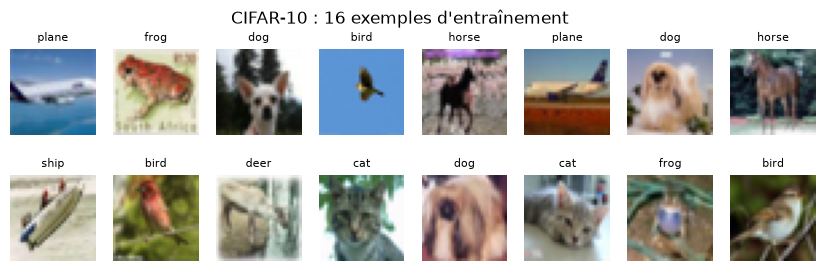

In [5]:
def plot_grid(images, titles, suptitle, columns=8):
    """Affiche une grille d'images `[3, H, W]` ou `[1, H, W]` dans [0, 1]."""
    rows = math.ceil(len(images) / columns)
    figure, axes = plt.subplots(rows, columns, figsize=(columns * 1.3, rows * 1.5), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, image, title in zip(axes.ravel(), images, titles):
        image = image.detach().cpu().clamp(0, 1)
        if image.shape[0] == 1:
            ax.imshow(image[0], cmap="gray")
        else:
            ax.imshow(image.permute(1, 2, 0))  # [C, H, W] → [H, W, C]
        ax.set_title(title, fontsize=8)
    figure.suptitle(suptitle)
    plt.show()


indices = torch.randint(len(training_data), size=(16,)).tolist()
plot_grid(
    [training_data[i][0] for i in indices],
    [classes[training_data[i][1]] for i in indices],
    "CIFAR-10 : 16 exemples d'entraînement",
)

## 2. Préparer les données

Découpage train / validation comme pour MNIST, avec `random_split`. Le test
officiel (10 000 images) est gardé à part.

In [6]:
train_split, validation_split = random_split(
    training_data, [0.8, 0.2], generator=torch.Generator().manual_seed(SEED)
)
print(f"train {len(train_split)}   val {len(validation_split)}   test {len(test_data)}")

train 40000   val 10000   test 10000


Avec trois canaux, la normalisation demande **une moyenne et un écart-type par
canal**. Le bleu n'a pas les mêmes statistiques que le rouge : une seule
valeur pour les trois les laisserait mal centrés.

In [7]:
train_pixels = torch.from_numpy(training_data.data[train_split.indices]).float() / 255  # (n, 32, 32, 3)
mean = train_pixels.mean(dim=(0, 1, 2))
std = train_pixels.std(dim=(0, 1, 2))
print(f"moyenne par canal (R, G, B)    : {[round(v, 4) for v in mean.tolist()]}")
print(f"écart-type par canal (R, G, B) : {[round(v, 4) for v in std.tolist()]}")

normalize = v2.Normalize(mean=mean.tolist(), std=std.tolist())
normalizing_transform = v2.Compose([transform, normalize])

moyenne par canal (R, G, B)    : [0.4919, 0.4825, 0.4468]
écart-type par canal (R, G, B) : [0.2472, 0.2436, 0.2618]


`random_split` renvoie des `Subset` qui référencent `training_data`, donc sa
transformation, qui ne normalise pas. On recrée un jeu de données avec la
transformation normalisante et on le redécoupe avec les **mêmes indices**.

In [8]:
normalized_data = datasets.CIFAR10(root=DATA_DIR, train=True, transform=normalizing_transform)
normalized_test = datasets.CIFAR10(root=DATA_DIR, train=False, transform=normalizing_transform)

train_dataloader = DataLoader(Subset(normalized_data, train_split.indices), batch_size=64, shuffle=True)
validation_dataloader = DataLoader(Subset(normalized_data, validation_split.indices), batch_size=64, shuffle=False)
test_dataloader = DataLoader(normalized_test, batch_size=64, shuffle=False)

train_features, train_labels = next(iter(train_dataloader))
print(f"features batch : {tuple(train_features.shape)}  {train_features.dtype}")
print(f"labels batch   : {tuple(train_labels.shape)}  {train_labels.dtype}")

features batch : (64, 3, 32, 32)  torch.float32
labels batch   : (64,)  torch.int64


## 3. Un réseau convolutif

### Pourquoi une convolution

Un `nn.Linear` relie **chaque** pixel d'entrée à **chaque** neurone. Il ignore
que deux pixels voisins ont quelque chose à voir l'un avec l'autre : si on
mélange l'ordre des pixels de façon fixe, il apprend exactement aussi bien.

Une **convolution** (`nn.Conv2d`) fait deux hypothèses sur les images :

- **localité** : un neurone ne regarde qu'une petite fenêtre, le *kernel*.
  Ici **3×3** : un bord, un coin, une tache de couleur se détectent
  localement ;
- **partage des poids** : le **même** kernel glisse sur toute l'image. Un bord
  se ressemble, qu'il soit en haut à gauche ou en bas à droite.

Chaque kernel produit une carte d'activations, une *feature map*. Une couche
avec 32 kernels produit 32 feature maps : ce sont ses **canaux de sortie**.
Un kernel 3×3 sur une image RGB a `3 × 3 × 3 = 27` poids, un par pixel de la
fenêtre et par canal d'entrée.

Deux réglages contrôlent la taille des cartes :

- `padding=1` ajoute un bord de zéros : la convolution ne rogne plus l'image,
  32×32 reste 32×32 ;
- `nn.MaxPool2d(2)` garde le maximum de chaque bloc 2×2 : hauteur et largeur
  divisées par deux.

On empile des kernels 3×3 : deux 3×3 successifs voient la même fenêtre 5×5
qu'un seul kernel 5×5, avec moins de poids et une non-linéarité de plus.
Le réseau : deux blocs de deux convolutions suivies d'un pooling, puis un
classifieur linéaire qui prend la décision.

In [9]:
class CNN(nn.Module):
    """Deux blocs [conv 3×3 → ReLU → conv 3×3 → ReLU → pool], puis 4 096 → 128 → 10."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),    # [3, 32, 32]  → [32, 32, 32]
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),   # → [32, 32, 32]
            nn.ReLU(),
            nn.MaxPool2d(2),                               # → [32, 16, 16]
            nn.Conv2d(32, 64, kernel_size=3, padding=1),   # → [64, 16, 16]
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),   # → [64, 16, 16]
            nn.ReLU(),
            nn.MaxPool2d(2),                               # → [64, 8, 8]
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  # → 4 096
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class MLP(nn.Module):
    """Le MLP de MNIST, avec une entrée de 3 072 valeurs."""

    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.linear_relu_stack(self.flatten(x))


print(CNN())
print(f"\nCNN : {sum(p.numel() for p in CNN().parameters()):>9,} paramètres")
print(f"MLP : {sum(p.numel() for p in MLP().parameters()):>9,} paramètres")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU()
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

CNN :   591,274 paramètres
MLP : 1,841,162 paramètres


### Suivre les formes, couche par couche

Une erreur fréquente en écrivant un CNN : le `64 * 8 * 8` de la première
couche linéaire. Il faut savoir quelle taille d'image sort des convolutions.
Pour chaque dimension spatiale :

    sortie = (entrée − kernel + 2 × padding) / stride + 1

Avec un kernel 3, un padding 1 et un stride 1, la taille est conservée. Seuls
les poolings la divisent : 32 → 16 → 8. Plutôt que de calculer à la main, on
fait passer un batch et on imprime.

In [10]:
x = train_features[:2]
print(f"entrée : {tuple(x.shape)}")
for layer in [*CNN().features, nn.Flatten()]:
    x = layer(x)
    print(f"  {layer.__class__.__name__:<10} → {tuple(x.shape)}")

entrée : (2, 3, 32, 32)
  Conv2d     → (2, 32, 32, 32)
  ReLU       → (2, 32, 32, 32)
  Conv2d     → (2, 32, 32, 32)
  ReLU       → (2, 32, 32, 32)
  MaxPool2d  → (2, 32, 16, 16)
  Conv2d     → (2, 64, 16, 16)
  ReLU       → (2, 64, 16, 16)
  Conv2d     → (2, 64, 16, 16)
  ReLU       → (2, 64, 16, 16)
  MaxPool2d  → (2, 64, 8, 8)
  Flatten    → (2, 4096)


### Compter les paramètres

Le partage des poids rend les convolutions économes : la première couche du
CNN n'a que `32 × (3 × 3 × 3) + 32 = 896` paramètres, quelle que soit la taille
de l'image. La première couche du MLP en a `3 072 × 512 + 512`. Le CNN a
**moins** de paramètres que le MLP : s'il fait mieux, ce n'est pas une
question de taille.

In [11]:
first_conv = CNN().features[0]
first_linear = MLP().linear_relu_stack[0]
print(f"première couche du CNN : {sum(p.numel() for p in first_conv.parameters()):>9,} paramètres")
print(f"première couche du MLP : {sum(p.numel() for p in first_linear.parameters()):>9,} paramètres")

première couche du CNN :       896 paramètres
première couche du MLP : 1,573,376 paramètres


## 4. Entraîner : CNN contre MLP

Mêmes boucles d'entraînement et de test que pour MNIST. Comparaison
expérimentale : **mêmes données, même optimiseur, même budget**, une seule
chose change, l'architecture.

Les courbes partent dans TensorBoard, un run par modèle :

    tensorboard --logdir runs/cifar10

In [12]:
def train_loop(dataloader, model, loss_fn, optimizer, verbose=True, writer=None, epoch=None):
    """Un passage complet sur le jeu d'entraînement."""
    size = len(dataloader.dataset)
    model.train()
    running_loss, seen = 0.0, 0

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)                 # 1. forward
        loss = loss_fn(pred, y)         # 2. loss

        loss.backward()                 # 3. backward
        optimizer.step()                # 4. step
        optimizer.zero_grad()           # 5. remise à zéro des gradients

        running_loss += loss.item() * len(X)
        seen += len(X)
        if verbose and batch % 100 == 0:
            print(f"    loss: {loss.item():>7f}  [{seen:>5d}/{size:>5d}]")

    train_loss = running_loss / seen
    if writer is not None:
        writer.add_scalar("loss/train", train_loss, epoch)
        writer.add_scalar("lr", optimizer.param_groups[0]["lr"], epoch)
    return train_loss


def test_loop(dataloader, model, loss_fn, verbose=True, writer=None, epoch=None):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0.0, 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    if verbose:
        print(f"  Test Error: Accuracy {100 * correct:>0.1f}%, Avg loss {test_loss:>8f}")
    if writer is not None:
        writer.add_scalar("loss/val", test_loss, epoch)
        writer.add_scalar("accuracy/val", correct, epoch)
    return test_loss, correct

In [13]:
EPOCHS = 10
learning_rate = 1e-3
loss_fn = nn.CrossEntropyLoss()

models, val_loss, val_accuracy = {}, {}, {}
for name, model_class in (("mlp", MLP), ("cnn", CNN)):
    print(f"===== {name}")
    torch.manual_seed(SEED)  # mêmes poids initiaux et même ordre de batchs d'un modèle à l'autre
    model = model_class().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

    with make_writer(name) as writer:
        for epoch in range(1, EPOCHS + 1):
            print(f"Epoch {epoch}")
            train_loop(train_dataloader, model, loss_fn, optimizer, verbose=False, writer=writer, epoch=epoch)
            val_loss[name], val_accuracy[name] = test_loop(validation_dataloader, model, loss_fn, writer=writer, epoch=epoch)
    models[name] = model

===== mlp
Epoch 1
  Test Error: Accuracy 44.2%, Avg loss 1.589689
Epoch 2
  Test Error: Accuracy 47.5%, Avg loss 1.483867
Epoch 3
  Test Error: Accuracy 47.6%, Avg loss 1.507671
Epoch 4
  Test Error: Accuracy 50.2%, Avg loss 1.455198
Epoch 5
  Test Error: Accuracy 50.8%, Avg loss 1.466344
Epoch 6
  Test Error: Accuracy 51.5%, Avg loss 1.482370
Epoch 7
  Test Error: Accuracy 51.1%, Avg loss 1.526711
Epoch 8
  Test Error: Accuracy 50.7%, Avg loss 1.640174
Epoch 9
  Test Error: Accuracy 51.5%, Avg loss 1.603115
Epoch 10
  Test Error: Accuracy 51.3%, Avg loss 1.659677
===== cnn
Epoch 1
  Test Error: Accuracy 59.9%, Avg loss 1.123369
Epoch 2
  Test Error: Accuracy 69.1%, Avg loss 0.894308
Epoch 3
  Test Error: Accuracy 72.2%, Avg loss 0.813696
Epoch 4
  Test Error: Accuracy 73.6%, Avg loss 0.794713
Epoch 5
  Test Error: Accuracy 74.9%, Avg loss 0.783246
Epoch 6
  Test Error: Accuracy 73.4%, Avg loss 0.919947
Epoch 7
  Test Error: Accuracy 72.9%, Avg loss 1.011156
Epoch 8
  Test Error: Accur

Dans TensorBoard, cocher `mlp` et `cnn` et comparer :

- `accuracy/val` : qui apprend le mieux ;
- `loss/train` contre `loss/val` : qui **surapprend**. Une perte de validation
  qui **remonte** alors que celle d'entraînement continue de descendre est le
  signe d'un modèle qui apprend les images par cœur plutôt que les classes.
  Le chapitre 7 y remédie.

### Regarder ce que le CNN rate

Les erreurs sont souvent défendables : chats et chiens, camions et voitures,
cerfs et chevaux. À 32×32 pixels, un humain hésite aussi.

2803 erreurs du CNN sur 10000 images de validation


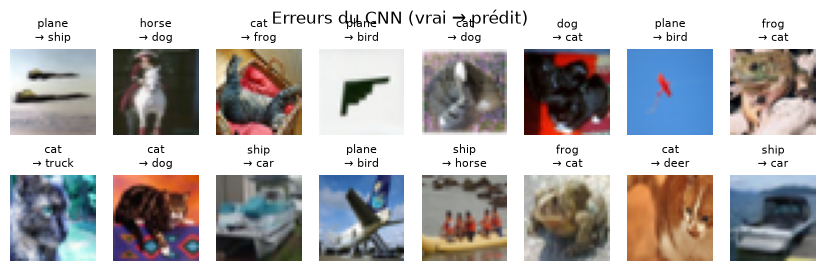

In [14]:
model = models["cnn"]
model.eval()

predictions = []
with torch.no_grad():
    for X, _ in validation_dataloader:
        predictions.append(model(X.to(device)).argmax(1).cpu())
predictions = torch.cat(predictions)
labels = torch.tensor([training_data.targets[i] for i in validation_split.indices])

mistakes = (predictions != labels).nonzero(as_tuple=True)[0]
print(f"{len(mistakes)} erreurs du CNN sur {len(labels)} images de validation")

mistakes = mistakes[:16]
plot_grid(
    [training_data[validation_split.indices[i]][0] for i in mistakes],
    [f"{classes[labels[i]]}\n→ {classes[predictions[i]]}" for i in mistakes],
    "Erreurs du CNN (vrai → prédit)",
)

## 5. Ce que le CNN a appris

### Les filtres de la première convolution

Les 32 kernels 3×3 de la première couche, affichés comme de minuscules images
couleur. Chacun est un détecteur de motif local : un contraste entre une
colonne et la suivante, une couleur opposée à une autre. À 9 pixels, ils sont
difficiles à lire à l'œil ; on regarde plutôt ce qu'ils **produisent**.

### Les feature maps

Ce que produit la première convolution (après ReLU) sur une image : 32 cartes
32×32, une par filtre. Chaque carte s'allume là où son motif est présent. Même
image, 32 lectures différentes : certaines cartes gardent les contours, d'autres
les grandes zones claires. C'est le premier étage d'une hiérarchie : bords,
puis formes, puis parties d'objets dans les couches suivantes.

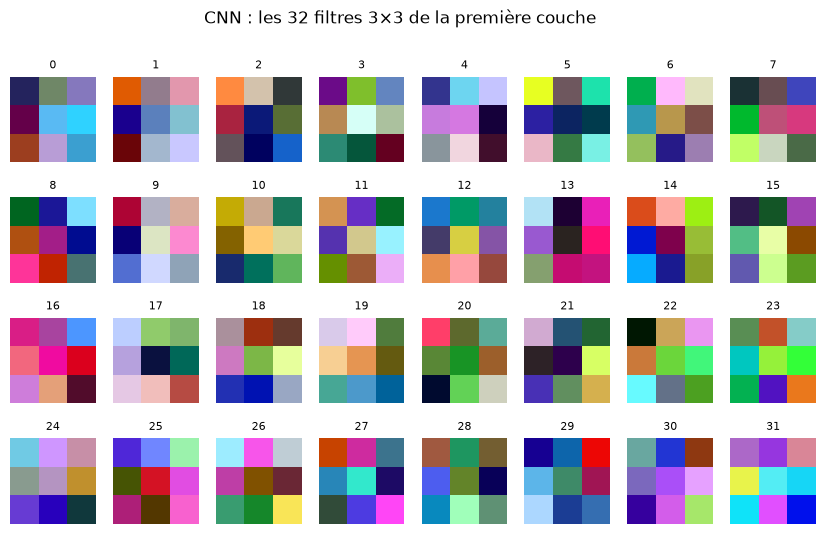

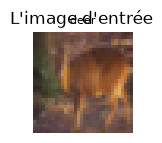

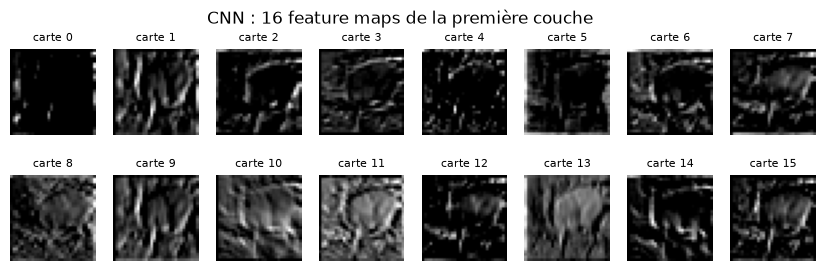

In [15]:
def rescale01(batch):
    """Ramène chaque élément d'un batch dans [0, 1], indépendamment des autres.

    Indispensable pour afficher des poids ou des activations, dont l'échelle
    n'a rien à voir avec celle d'une image.
    """
    flat = batch.detach().flatten(1)
    shape = (-1,) + (1,) * (batch.dim() - 1)
    low = flat.min(1).values.view(shape)
    high = flat.max(1).values.view(shape)
    return (batch.detach() - low) / (high - low).clamp(min=1e-8)


cnn = models["cnn"]
filters = rescale01(cnn.features[0].weight.cpu())  # [32, 3, 3, 3]
plot_grid(filters, [str(i) for i in range(32)], "CNN : les 32 filtres 3×3 de la première couche")

example, _ = next(iter(validation_dataloader))
with torch.no_grad():
    feature_maps = cnn.features[:2](example[:1].to(device))[0].cpu()  # conv1 + ReLU → [32, 32, 32]
feature_maps = rescale01(feature_maps.unsqueeze(1))                   # [32, 1, 32, 32]

plot_grid(
    [training_data[validation_split.indices[0]][0]],
    [classes[training_data[validation_split.indices[0]][1]]],
    "L'image d'entrée",
    columns=1,
)
plot_grid(feature_maps[:16], [f"carte {i}" for i in range(16)], "CNN : 16 feature maps de la première couche")

## 6. Le biais inductif : mélanger les pixels

Un **biais inductif** est une hypothèse qu'une architecture fait sur les
données avant d'en avoir vu une seule. Le CNN suppose que les pixels voisins
sont liés. Le MLP ne suppose rien.

Pour le prouver, on applique à **toutes** les images la **même** permutation
des pixels, identique pour les trois canaux. Aucune information n'est perdue,
la permutation est inversible, mais les images deviennent du bruit pour un œil
humain.

- Pour le **MLP**, rien n'a changé : une permutation fixe de ses entrées
  revient à permuter les colonnes de sa première matrice de poids. Il doit
  apprendre aussi bien, aux fluctuations près.
- Pour le **CNN**, les fenêtres 3×3 ne contiennent plus des pixels voisins
  dans la scène. Son hypothèse est fausse, il doit perdre son avantage.

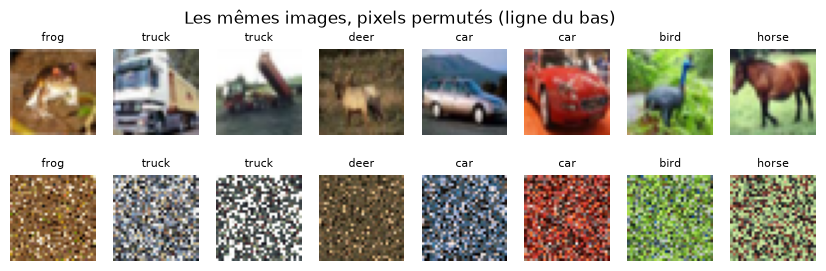

===== mlp, pixels permutés
Epoch 1
  Test Error: Accuracy 44.8%, Avg loss 1.576936
Epoch 2
  Test Error: Accuracy 47.0%, Avg loss 1.514465
Epoch 3
  Test Error: Accuracy 48.4%, Avg loss 1.474849
Epoch 4
  Test Error: Accuracy 49.7%, Avg loss 1.455491
Epoch 5
  Test Error: Accuracy 49.1%, Avg loss 1.478237
Epoch 6
  Test Error: Accuracy 50.2%, Avg loss 1.476805
Epoch 7
  Test Error: Accuracy 50.5%, Avg loss 1.525251
Epoch 8
  Test Error: Accuracy 50.5%, Avg loss 1.576345
Epoch 9
  Test Error: Accuracy 50.4%, Avg loss 1.599455
Epoch 10
  Test Error: Accuracy 51.5%, Avg loss 1.594263
===== cnn, pixels permutés
Epoch 1
  Test Error: Accuracy 42.0%, Avg loss 1.611638
Epoch 2
  Test Error: Accuracy 46.5%, Avg loss 1.502217
Epoch 3
  Test Error: Accuracy 49.2%, Avg loss 1.431726
Epoch 4
  Test Error: Accuracy 50.6%, Avg loss 1.386665
Epoch 5
  Test Error: Accuracy 51.4%, Avg loss 1.395286
Epoch 6
  Test Error: Accuracy 51.0%, Avg loss 1.461918
Epoch 7
  Test Error: Accuracy 50.8%, Avg loss 1.

In [16]:
permutation = torch.randperm(32 * 32, generator=torch.Generator().manual_seed(SEED))


def permute_pixels(image):
    """Applique la même permutation spatiale à une image `[3, 32, 32]`."""
    return image.flatten(1)[:, permutation].reshape(image.shape)


originals = [training_data[i][0] for i in range(8)]
plot_grid(
    originals + [permute_pixels(image) for image in originals],
    [classes[training_data[i][1]] for i in range(8)] * 2,
    "Les mêmes images, pixels permutés (ligne du bas)",
)

permuting_transform = v2.Compose([normalizing_transform, v2.Lambda(permute_pixels)])
permuted_data = datasets.CIFAR10(root=DATA_DIR, train=True, transform=permuting_transform)
permuted_train_dataloader = DataLoader(Subset(permuted_data, train_split.indices), batch_size=64, shuffle=True)
permuted_validation_dataloader = DataLoader(Subset(permuted_data, validation_split.indices), batch_size=64, shuffle=False)

for name, model_class in (("mlp", MLP), ("cnn", CNN)):
    print(f"===== {name}, pixels permutés")
    torch.manual_seed(SEED)
    model = model_class().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

    with make_writer(f"{name}_permuted") as writer:
        for epoch in range(1, EPOCHS + 1):
            print(f"Epoch {epoch}")
            train_loop(permuted_train_dataloader, model, loss_fn, optimizer, verbose=False, writer=writer, epoch=epoch)
            val_loss[f"{name}_permuted"], val_accuracy[f"{name}_permuted"] = test_loop(
                permuted_validation_dataloader, model, loss_fn, writer=writer, epoch=epoch
            )

for name in ("mlp", "cnn"):
    print(f"{name} : {val_accuracy[name]:.1%} sur les images, {val_accuracy[f'{name}_permuted']:.1%} sur les pixels permutés")

Leçon : le CNN n'est pas « meilleur » dans l'absolu. Il est meilleur **sur des
images**, parce que son hypothèse est vraie pour des images. Sur des données
sans structure spatiale (un tableau de mesures, un vecteur de features), cette
hypothèse ne vaut rien. Choisir une architecture, c'est choisir quelles
hypothèses on fait sur ses données.

## 7. Lutter contre le surapprentissage

Le CNN comme le MLP apprennent le train par cœur : leur perte d'entraînement
continue de descendre, leur perte de validation remonte. Plusieurs remèdes
existent, qui agissent à des endroits différents :

- **Augmentation de données** : on modifie ce que le réseau voit, en
  transformant chaque image à chaque epoch ;
- **Dropout** (`nn.Dropout(p)`) : à chaque step d'entraînement, chaque
  activation est mise à zéro avec la probabilité `p`. Le réseau ne peut plus
  compter sur un neurone précis, il doit répartir l'information. Désactivé
  par `model.eval()`. On le place typiquement entre les couches linéaires du
  classifieur ;
- **BatchNorm** (`nn.BatchNorm2d(canaux)`, après une convolution) : normalise
  les activations de chaque canal avec la moyenne et l'écart-type **du
  batch**, puis apprend une échelle et un décalage. Son rôle premier est de
  stabiliser et d'accélérer l'entraînement ; l'effet régularisant est
  secondaire, il vient du bruit que les statistiques d'un batch à l'autre
  ajoutent. En évaluation, elle utilise des statistiques moyennes accumulées
  pendant l'entraînement : `model.eval()` change donc son comportement ;
- **LayerNorm** (`nn.LayerNorm`) : normalise les features d'**un même
  exemple**, sans dépendre des autres images du batch. Même comportement en
  entraînement et en évaluation, et elle marche avec de petits batchs. C'est
  la normalisation standard des transformers ; pour les CNN d'images,
  BatchNorm reste le choix courant, c'est celle qu'on utilise ici.

On les teste dans l'ordre : l'augmentation seule, puis dropout et BatchNorm
seuls, puis les deux ensemble. Même optimiseur, même nombre d'epochs.

### Augmentation de données

On transforme chaque image aléatoirement, à chaque epoch, par des
modifications qui **ne changent pas sa classe** :

- `RandomHorizontalFlip` : un chat regardant à gauche reste un chat ;
- `RandomCrop(32, padding=4)` : on ajoute 4 pixels de bord, puis on recadre au
  hasard, soit un décalage aléatoire d'au plus 4 pixels.

Le modèle ne voit jamais deux fois exactement la même image : il ne peut plus
les apprendre par cœur. Ces transformations vivent dans le `v2.Compose`, elles
sont tirées à chaque accès.

Attention à ce qui **n'est pas** une augmentation valide : un retournement
vertical (un bateau à l'envers n'existe pas dans le jeu de test), ou une
rotation à 90° d'un « 6 » de MNIST, qui en fait un « 9 ». L'augmentation est
une connaissance du domaine, pas une recette.

Elle ne s'applique **qu'au train** : la validation et le test restent intacts.

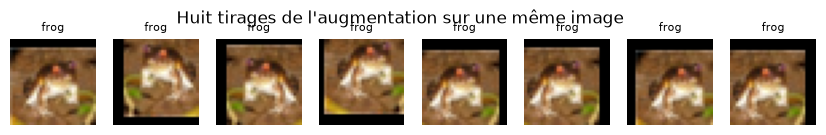

In [17]:
augmentation = v2.Compose(
    [
        v2.RandomCrop(32, padding=4),  # bord à 0 = noir
        v2.RandomHorizontalFlip(),
    ]
)

augmented_view = datasets.CIFAR10(root=DATA_DIR, train=True, transform=v2.Compose([transform, augmentation]))
torch.manual_seed(SEED)
plot_grid(
    [augmented_view[0][0] for _ in range(8)],
    [classes[augmented_view[0][1]]] * 8,
    "Huit tirages de l'augmentation sur une même image",
)

In [18]:
augmenting_transform = v2.Compose([transform, augmentation, normalize])
augmented_data = datasets.CIFAR10(root=DATA_DIR, train=True, transform=augmenting_transform)
augmented_train_dataloader = DataLoader(Subset(augmented_data, train_split.indices), batch_size=64, shuffle=True)

print("===== cnn, avec augmentation")
torch.manual_seed(SEED)
model = CNN().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

with make_writer("cnn_augmentation") as writer:
    for epoch in range(1, EPOCHS + 1):
        print(f"Epoch {epoch}")
        train_loop(augmented_train_dataloader, model, loss_fn, optimizer, verbose=False, writer=writer, epoch=epoch)
        val_loss["cnn_augmentation"], val_accuracy["cnn_augmentation"] = test_loop(
            validation_dataloader, model, loss_fn, writer=writer, epoch=epoch
        )
models["cnn_augmentation"] = model
print(f"\ncnn : {val_accuracy['cnn']:.1%} → {val_accuracy['cnn_augmentation']:.1%} avec augmentation")

===== cnn, avec augmentation
Epoch 1
  Test Error: Accuracy 54.1%, Avg loss 1.279575
Epoch 2
  Test Error: Accuracy 64.4%, Avg loss 0.997553
Epoch 3
  Test Error: Accuracy 69.2%, Avg loss 0.891841
Epoch 4
  Test Error: Accuracy 71.5%, Avg loss 0.831238
Epoch 5
  Test Error: Accuracy 72.2%, Avg loss 0.801750
Epoch 6
  Test Error: Accuracy 75.0%, Avg loss 0.723182
Epoch 7
  Test Error: Accuracy 75.4%, Avg loss 0.706144
Epoch 8
  Test Error: Accuracy 76.3%, Avg loss 0.684075
Epoch 9
  Test Error: Accuracy 76.2%, Avg loss 0.694266
Epoch 10
  Test Error: Accuracy 78.4%, Avg loss 0.638709

cnn : 72.0% → 78.4% avec augmentation


L'augmentation rend chaque epoch plus difficile : la perte d'entraînement
descend moins vite, c'est voulu. Ce qui compte est la validation, et l'écart
entre les deux courbes dans TensorBoard.

### Dropout et BatchNorm

On met le CNN à jour : une `BatchNorm2d` après chaque convolution, avant la
ReLU, et un `Dropout(0.25)` avant la dernière couche linéaire. Les kernels, les
canaux et les tailles sont inchangés.

Le taux de dropout est un réglage. Le classique 0,5 freinait trop
l'apprentissage en 10 epochs, surtout combiné à l'augmentation ; 0,25 a été
retenu sur la **validation**, jamais sur le test.

In [19]:
class RegularizedCNN(nn.Module):
    """Le CNN, avec BatchNorm après chaque convolution et un dropout avant la sortie."""

    def __init__(self, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print(f"RegularizedCNN : {sum(p.numel() for p in RegularizedCNN().parameters()):>9,} paramètres")

RegularizedCNN :   591,658 paramètres


In [20]:
for name, dataloader in (
    ("cnn_regularized", train_dataloader),
    ("cnn_regularized_augmentation", augmented_train_dataloader),
):
    print(f"===== {name}")
    torch.manual_seed(SEED)
    model = RegularizedCNN().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

    with make_writer(name) as writer:
        for epoch in range(1, EPOCHS + 1):
            print(f"Epoch {epoch}")
            train_loop(dataloader, model, loss_fn, optimizer, verbose=False, writer=writer, epoch=epoch)
            val_loss[name], val_accuracy[name] = test_loop(validation_dataloader, model, loss_fn, writer=writer, epoch=epoch)
    models[name] = model

===== cnn_regularized
Epoch 1
  Test Error: Accuracy 62.0%, Avg loss 1.058896
Epoch 2
  Test Error: Accuracy 61.8%, Avg loss 1.107483
Epoch 3
  Test Error: Accuracy 67.4%, Avg loss 0.923532
Epoch 4
  Test Error: Accuracy 72.5%, Avg loss 0.794242
Epoch 5
  Test Error: Accuracy 74.4%, Avg loss 0.735563
Epoch 6
  Test Error: Accuracy 76.4%, Avg loss 0.679329
Epoch 7
  Test Error: Accuracy 76.5%, Avg loss 0.716270
Epoch 8
  Test Error: Accuracy 76.7%, Avg loss 0.689630
Epoch 9
  Test Error: Accuracy 74.4%, Avg loss 0.795676
Epoch 10
  Test Error: Accuracy 77.5%, Avg loss 0.671540
===== cnn_regularized_augmentation
Epoch 1
  Test Error: Accuracy 54.9%, Avg loss 1.228557
Epoch 2
  Test Error: Accuracy 63.5%, Avg loss 1.015163
Epoch 3
  Test Error: Accuracy 61.7%, Avg loss 1.120809
Epoch 4
  Test Error: Accuracy 68.2%, Avg loss 0.907729
Epoch 5
  Test Error: Accuracy 69.6%, Avg loss 0.851497
Epoch 6
  Test Error: Accuracy 74.3%, Avg loss 0.730955
Epoch 7
  Test Error: Accuracy 72.1%, Avg loss

### Le bilan

Les quatre CNN, à la dernière epoch, sur la validation. Une perte de
validation basse compte autant que l'exactitude : c'est elle qui remonte
quand le modèle surapprend. Dans TensorBoard, cocher `cnn`, `cnn_augmentation`,
`cnn_regularized` et `cnn_regularized_augmentation` pour comparer les courbes.

In [21]:
for name in ("cnn", "cnn_augmentation", "cnn_regularized", "cnn_regularized_augmentation"):
    print(f"{name:<30} exactitude val {val_accuracy[name]:.1%}   perte val {val_loss[name]:.3f}")

cnn                            exactitude val 72.0%   perte val 1.417
cnn_augmentation               exactitude val 78.4%   perte val 0.639
cnn_regularized                exactitude val 77.5%   perte val 0.672
cnn_regularized_augmentation   exactitude val 75.4%   perte val 0.714


Ce qu'on lit :

- **dropout + BatchNorm** (`cnn_regularized`) : la perte de validation ne
  remonte plus, elle est **divisée par deux** par rapport au `cnn`, et
  l'exactitude gagne plusieurs points. Même architecture de base, mêmes
  données, même budget : le surapprentissage était bien le facteur limitant ;
- **l'augmentation seule** (`cnn_augmentation`) fait au moins aussi bien : elle
  agit sur les données, là où dropout et BatchNorm agissent sur le réseau ;
- **les deux ensemble** ne font pas mieux que l'un des deux en 10 epochs.
  Chaque remède ralentit l'apprentissage : la perte d'entraînement de
  `cnn_regularized_augmentation` est la plus haute des quatre et descend encore
  à la dernière epoch. Le modèle sous-apprend plus qu'il ne surapprend, il
  lui faudrait plus d'epochs. Régulariser n'est pas gratuit : trop, on
  passe de l'autre côté.

## 8. Le test, une seule fois

Toutes les décisions sont prises. On évalue chaque modèle retenu sur les
10 000 images de test, une fois.

In [22]:
for name in ("mlp", "cnn", "cnn_augmentation", "cnn_regularized", "cnn_regularized_augmentation"):
    _, test_accuracy = test_loop(test_dataloader, models[name], loss_fn, verbose=False)
    print(f"{name:<30} {sum(p.numel() for p in models[name].parameters()):>9,} paramètres   {test_accuracy:.1%} d'exactitude sur le test")

mlp                            1,841,162 paramètres   51.1% d'exactitude sur le test
cnn                              591,274 paramètres   72.8% d'exactitude sur le test
cnn_augmentation                 591,274 paramètres   78.4% d'exactitude sur le test
cnn_regularized                  591,658 paramètres   77.3% d'exactitude sur le test
cnn_regularized_augmentation     591,658 paramètres   74.6% d'exactitude sur le test
